# 01. EDA исходного текстового набора данных — UCI SMS Spam Collection

| Параметр | Значение |
|---|---|
| Набор данных | UCI SMS Spam Collection v.1 |
| Модальность | текст (SMS) |
| Задача | бинарная классификация, классы `ham` / `spam` |
| Лицензия | CC BY 4.0 |
| Источник | https://archive.ics.uci.edu/dataset/228/sms+spam+collection |
| Файл данных | `SMSSpamCollection` (TSV без заголовка, 2 колонки) |
| Дата обращения | 22.10.2026 |
| Ноутбук | версия 1.0 от 22.10.2026 |
| Исполнители | Якунченков К. А., Графов Г. П. |

**Назначение.** Зафиксировать характеристики исходного набора до любого обогащения:
объём, баланс классов, длины сообщений, дубликаты и шаблоны, простые признаки,
лексический состав. Результаты используются как базовая линия в разделе
«Анализ данных» отчёта и как вход для проектирования разбиения на фолды.

**Выходные артефакты** (сохраняются в `reports/`):

* `tables/sms_dataset_passport.csv` — паспорт файла и контрольные суммы;
* `tables/sms_class_balance.csv` — баланс классов;
* `tables/sms_length_stats.csv` — статистика длин по классам;
* `tables/sms_duplicates.csv` — дубликаты и группы шаблонов;
* `tables/sms_feature_flags.csv` — частота простых признаков по классам;
* `tables/sms_baseline_split_effect.csv` — эффект утечки при случайном разбиении;
* `figures/01_sms_class_balance.png`, `02_sms_length_dist.png`,
  `03_sms_duplicate_groups.png`, `04_sms_feature_flags.png`,
  `05_sms_top_tokens.png`, `06_sms_calibration.png`;
* `tables/sms_cv_repeats.csv`, `tables/sms_baseline_ci.csv`, `tables/sms_calibration.csv`,
  `tables/sms_thresholds.csv`, `tables/sms_power_analysis.csv`, `tables/sms_mcnemar_critical.csv`,
  `tables/sms_results_template.csv` — оценивание, калибровка и чувствительность (разделы 9–12).

**Требования воспроизводимости.** Фиксированный `RANDOM_STATE`, контрольная сумма
входного файла, фиксированные версии библиотек (печатаются в разделе 0).

## 0. Окружение, импорты и константы

In [1]:
# В Google Colab все зависимости уже установлены. Локально при первом запуске
# выполнить один раз:
# %pip install -q pandas numpy matplotlib scikit-learn

import hashlib
import io
import platform
import re
import sys
import urllib.request
import zipfile
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    cohen_kappa_score,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict

print("Python     :", platform.python_version())
for m in (np, pd, matplotlib, sklearn):
    print(f"{m.__name__:11s}:", m.__version__)
print("Платформа  :", platform.platform())

Python     : 3.13.16
numpy      : 2.3.5
pandas     : 2.2.3
matplotlib : 3.10.9
sklearn    : 1.6.1
Платформа  : Linux-6.1.158+-x86_64-with-glibc2.41


In [2]:
# --- Режимы запуска: Google Colab / локальный репозиторий ---
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    ROOT = Path("/content/frame203")          # рабочая папка в Colab
else:
    ROOT = Path.cwd()
    if ROOT.name == "notebooks":              # запуск из папки notebooks/
        ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "raw" / "sms"
REPORTS = ROOT / "reports"
TABLES = REPORTS / "tables"
FIGURES = REPORTS / "figures"
for p in (DATA_DIR, TABLES, FIGURES):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
RAW_FILE = DATA_DIR / "SMSSpamCollection"
ZIP_FILE = DATA_DIR / "uci_sms_spam_collection.zip"
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Значение, полученное при первой загрузке 22.10.2026.
# Служит проверкой, что все участники работают с одной и той же версией файла.
EXPECTED_SHA256 = "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d"

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

print("ROOT      :", ROOT)
print("Данные    :", DATA_DIR)
print("Отчёты    :", REPORTS)

ROOT      : /tmp/run203
Данные    : /tmp/run203/data/raw/sms
Отчёты    : /tmp/run203/reports


## 1. Загрузка набора данных и контроль целостности

Файл `SMSSpamCollection` распространяется в архиве UCI. Контрольная сумма SHA-256
фиксирует конкретную версию данных: если у второго участника сумма отличается,
расхождение в метриках объясняется разными входными данными, а не моделью.

In [3]:
def sha256(path: Path) -> str:
    """SHA-256 файла, поблочное чтение."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def ensure_dataset() -> Path:
    """Скачивает и распаковывает архив UCI, если файла данных ещё нет."""
    if RAW_FILE.exists():
        print("Файл найден:", RAW_FILE)
        return RAW_FILE
    print("Скачивание:", DATA_URL)
    urllib.request.urlretrieve(DATA_URL, ZIP_FILE)
    with zipfile.ZipFile(ZIP_FILE) as z:
        z.extractall(DATA_DIR)
    print("Распаковано в", DATA_DIR)
    return RAW_FILE


ensure_dataset()
sms_sha = sha256(RAW_FILE)
print("\nSHA-256 файла данных :", sms_sha)
print("Ожидаемое значение    :", EXPECTED_SHA256)
print("Совпадение            :", sms_sha == EXPECTED_SHA256)
print("Размер, байт          :", RAW_FILE.stat().st_size)

Файл найден: /tmp/run203/data/raw/sms/SMSSpamCollection

SHA-256 файла данных : 7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d
Ожидаемое значение    : 7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d
Совпадение            : True
Размер, байт          : 477907


In [4]:
df = pd.read_csv(
    RAW_FILE,
    sep="\t",
    header=None,
    names=["label", "text"],
    quoting=3,           # в текстах встречаются кавычки и апострофы
    encoding="utf-8",
    dtype=str,
)

passport = pd.DataFrame(
    [
        ("источник", "UCI SMS Spam Collection v.1"),
        ("URL", DATA_URL),
        ("файл", RAW_FILE.name),
        ("SHA-256", sms_sha),
        ("строк в файле", len(df)),
        ("колонок", df.shape[1]),
        ("лицензия", "CC BY 4.0"),
        ("дата обращения", "22.10.2026"),
    ],
    columns=["показатель", "значение"],
)
passport.to_csv(TABLES / "sms_dataset_passport.csv", index=False)
display(passport)

print("\nПервые 3 записи:")
display(df.head(3))

,показатель,значение
0,источник,UCI SMS Spam Collection v.1
1,URL,https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip
2,файл,SMSSpamCollection
3,SHA-256,7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d
4,строк в файле,5574
5,колонок,2
6,лицензия,CC BY 4.0
7,дата обращения,22.10.2026



Первые 3 записи:


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...


## 2. Валидация схемы

Проверяются: состав меток, пропуски, пустые тексты, кодировка, наличие управляющих
символов. Ошибка схемы на этом шаге дешевле, чем на этапе обучения.

In [5]:
checks = {
    "строк": len(df),
    "уникальных меток": df["label"].nunique(),
    "метки": ", ".join(sorted(df["label"].unique())),
    "пропусков всего": int(df.isna().sum().sum()),
    "пустых текстов": int((df["text"].str.strip() == "").sum()),
    "текстов короче 3 символов": int((df["text"].str.len() < 3).sum()),
    "нелатинских символов (вхождений)": int(df["text"].str.count("[^\x00-\x7F]").sum()),
    "сообщений с нелатинскими символами": int((df["text"].str.count("[^\x00-\x7F]") > 0).sum()),
    "полных дублей строк": int(df.duplicated().sum()),
}
for k, v in checks.items():
    print(f"{k:38s}: {v}")

строк                                 : 5574
уникальных меток                      : 2
метки                                 : ham, spam
пропусков всего                       : 0
пустых текстов                        : 0
текстов короче 3 символов             : 4
нелатинских символов (вхождений)      : 633
сообщений с нелатинскими символами    : 483
полных дублей строк                   : 403


## 3. Баланс классов

Дисбаланс 86,6 % / 13,4 % означает, что `accuracy` неинформативна: константный ответ
`ham` даёт 0,866. Основная метрика эксперимента — macro-F1; для класса `spam`
дополнительно фиксируется PR-AUC.

,сообщений,доля
label,,
ham,4827.0,0.866
spam,747.0,0.134
итого,5574.0,1.000


Доля мажоритарного класса (ham): 0.8660
Accuracy константного ответа 'ham'          : 0.8660
Macro-F1 константного ответа                : 0.5000
Prevalence спама (базовая линия PR-AUC)     : 0.1340
Соотношение классов ham / spam              : 6.46 : 1


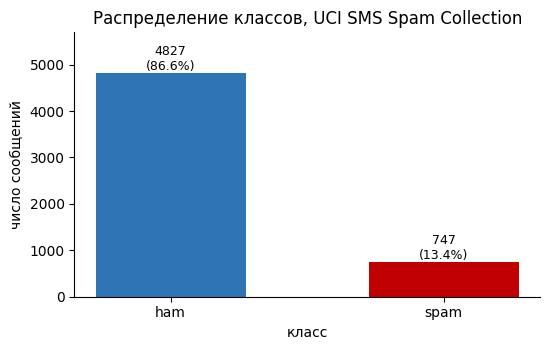

In [6]:
counts = df["label"].value_counts()
share = df["label"].value_counts(normalize=True)

balance = pd.DataFrame({"сообщений": counts, "доля": share.round(4)})
balance.loc["итого"] = [counts.sum(), share.sum()]
display(balance)

majority_share = share.max()
print(f"Доля мажоритарного класса ({counts.idxmax()}): {majority_share:.4f}")
print(f"Accuracy константного ответа 'ham'          : {majority_share:.4f}")
print("Macro-F1 константного ответа                : 0.5000")
print(f"Prevalence спама (базовая линия PR-AUC)     : {share['spam']:.4f}")
print(f"Соотношение классов ham / spam              : {counts['ham'] / counts['spam']:.2f} : 1")

balance.drop(index="итого").to_csv(TABLES / "sms_class_balance.csv")

fig, ax = plt.subplots(figsize=(5.6, 3.6))
bars = ax.bar(counts.index, counts.values, color=["#2E75B6", "#C00000"], width=0.55)
for b, v, s in zip(bars, counts.values, share.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v}\n({s:.1%})", ha="center", fontsize=9)
ax.set_title("Распределение классов, UCI SMS Spam Collection")
ax.set_xlabel("класс")
ax.set_ylabel("число сообщений")
ax.set_ylim(0, counts.max() * 1.18)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "01_sms_class_balance.png", dpi=160)
plt.show()

## 4. Длины сообщений

Длина в символах и словах — сильный признак в этом корпусе: спам построен по шаблону
(условия акции, короткий номер, тариф), ham — короткие бытовые реплики. Это объясняет,
почему линейная модель на TF-IDF работает на наборе почти идеально, и почему метрики
на таком наборе нельзя переносить на реальный фильтр без оговорок.

,класс,признак,среднее,ст. откл.,мин,макс,q5,q25,q50,q75,q95,q99
0,ham,len_chars,71.5,58.3,2,910,22.0,33.0,52.0,93.0,159.0,288.5
1,ham,len_words,14.3,11.5,1,171,4.0,7.0,11.0,19.0,33.0,57.0
2,spam,len_chars,138.7,28.9,13,223,72.0,133.0,149.0,157.0,162.0,174.1
3,spam,len_words,23.9,5.8,2,35,12.0,22.0,25.0,28.0,31.0,33.0


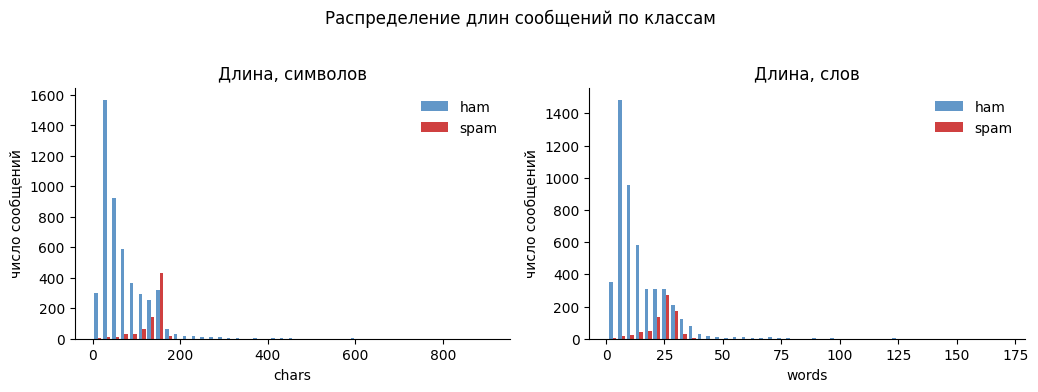

Доля сообщений короче 25 символов по классам:
label
ham     0.1028
spam    0.0040


In [7]:
df["len_chars"] = df["text"].str.len()
df["len_words"] = df["text"].str.split().str.len()

q = [0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
rows = []
for label, g in df.groupby("label"):
    for col in ("len_chars", "len_words"):
        r = {"класс": label, "признак": col, "среднее": g[col].mean(), "ст. откл.": g[col].std(),
             "мин": g[col].min(), "макс": g[col].max()}
        for p, v in zip(q, g[col].quantile(q)):
            r[f"q{int(p * 100)}"] = v
        rows.append(r)
length_stats = pd.DataFrame(rows).round(1)
display(length_stats)
length_stats.to_csv(TABLES / "sms_length_stats.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for ax, col, title in zip(axes, ("len_chars", "len_words"), ("Длина, символов", "Длина, слов")):
    data = [df.loc[df.label == l, col].values for l in ("ham", "spam")]
    ax.hist(data, bins=45, label=["ham", "spam"], color=["#2E75B6", "#C00000"], alpha=0.75)
    ax.set_title(title)
    ax.set_xlabel(col.replace("len_", ""))
    ax.set_ylabel("число сообщений")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Распределение длин сообщений по классам", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "02_sms_length_dist.png", dpi=160, bbox_inches="tight")
plt.show()

print("Доля сообщений короче 25 символов по классам:")
print(df.assign(short=df.len_chars < 25).groupby("label")["short"].mean().round(4).to_string())

## 5. Дубликаты и группы шаблонов

Два разных механизма утечки:

1. **Точные дубликаты** — одинаковый текст и метка. При случайном разбиении копии
   попадают и в train, и в test, метрика завышается.
2. **Шаблоны** — сообщения, различающиеся только номером телефона, суммой или ссылкой.
   После нормализации они совпадают и тоже должны попадать в один фолд.

Для обоих механизмов вычисляется `group_id`; разбиение выполняется по группам
(`StratifiedGroupKFold`), а не по отдельным строкам.

In [8]:
URL_RE = re.compile(r"(https?://\S+|www\.\S+)")
PHONE_RE = re.compile(r"\b(?:\+?\d[\d\s\-()]{6,}\d)\b")
NUM_RE = re.compile(r"\b\d+(?:[.,]\d+)?\b")
CURRENCY_RE = re.compile(r"[£$€]|\b(?:gbp|usd|eur|руб)\b", re.IGNORECASE)
UPPER_WORD_RE = re.compile(r"\b[A-Z]{3,}\b")


def normalise_for_templates(text: str) -> str:
    """Нормализация под поиск шаблонов: регистр, числа, ссылки, пунктуация."""
    t = text.lower()
    t = URL_RE.sub(" <url> ", t)
    t = PHONE_RE.sub(" <phone> ", t)
    t = NUM_RE.sub(" <num> ", t)
    t = re.sub(r"[^a-z<>\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


df["text_norm"] = df["text"].map(normalise_for_templates)

# --- точные дубликаты (текст + метка) ---
exact_dup_mask = df.duplicated(subset=["text"], keep="first")
n_exact_dup = int(exact_dup_mask.sum())

# --- группы шаблонов: одинаковый нормализованный текст, длина >= 20 символов ---
grouped = df.groupby("text_norm")
template_groups = grouped.size()
template_groups = template_groups[(template_groups > 1) & (template_groups.index.str.len() >= 20)]

df["group_id"] = df["text_norm"]
short_norm = df["text_norm"].str.len() < 20
df.loc[short_norm, "group_id"] = "short_" + df.index[short_norm].astype(str)

rows = [
    ("сообщений в файле", len(df)),
    ("уникальных текстов (точное совпадение)", df["text"].nunique()),
    ("точных дубликатов (строк сверх первой)", n_exact_dup),
    ("уникальных сообщений после удаления точных дублей", df["text"].nunique()),
    ("групп шаблонов (>= 2 сообщений, нормализованная длина >= 20)", int(len(template_groups))),
    ("строк в группах шаблонов", int(template_groups.sum())),
    ("строк, избыточных внутри групп шаблонов", int(template_groups.sum() - len(template_groups))),
    ("уникальных групп (group_id)", df["group_id"].nunique()),
    ("максимальный размер группы шаблонов", int(template_groups.max()) if len(template_groups) else 0),
]
dup_table = pd.DataFrame(rows, columns=["показатель", "значение"])
display(dup_table)
dup_table.to_csv(TABLES / "sms_duplicates.csv", index=False)

print("\nРазмеры групп шаблонов (топ-10):")
top_groups = template_groups.sort_values(ascending=False).head(10)
for norm_text, size in top_groups.items():
    print(f"  {size:2d} x  {norm_text[:110]}")

,показатель,значение
0,сообщений в файле,5574
1,уникальных текстов (точное совпадение),5171
2,точных дубликатов (строк сверх первой),403
3,уникальных сообщений после удаления точных дублей,5171
4,"групп шаблонов (>= 2 сообщений, нормализованная длина >= 20)",309
5,строк в группах шаблонов,747
6,"строк, избыточных внутри групп шаблонов",438
7,уникальных групп (group_id),5136
8,максимальный размер группы шаблонов,30



Размеры групп шаблонов (топ-10):
  30 x  sorry i ll call later
  12 x  i cant pick the phone right now pls send a message
   5 x  private your <num> account statement for shows <num> un redeemed s i m points call <phone> identifier code <nu
   4 x  <num> wonders in my world th you th ur style th ur smile th ur personality rd ur nature nd ur sms and st ur lo
   4 x  private your <num> account statement for <phone> shows <num> un redeemed s i m points call <phone> identifier 
   4 x  sorry i ll call later in meeting
   4 x  wen ur lovable bcums angry wid u dnt take it seriously coz being angry is d most childish n true way of showin
   4 x  camera you are awarded a sipix digital camera call <phone> fromm landline delivery within <num> days
   4 x  u have a secret admirer who is looking <num> make contact with u find out who they r reveal who thinks ur so s
   4 x  say this slowly god i love you amp i need you clean my heart with your blood send this to ten special people a


Крупнейшая группа шаблонов: 30 сообщений



,label,text
80,ham,"Sorry, I'll call later"
223,ham,"Sorry, I'll call later"
339,ham,"Sorry, I'll call later"
444,ham,"Sorry, I'll call later"
702,ham,"Sorry, I'll call later"
768,ham,"Sorry, I'll call later"


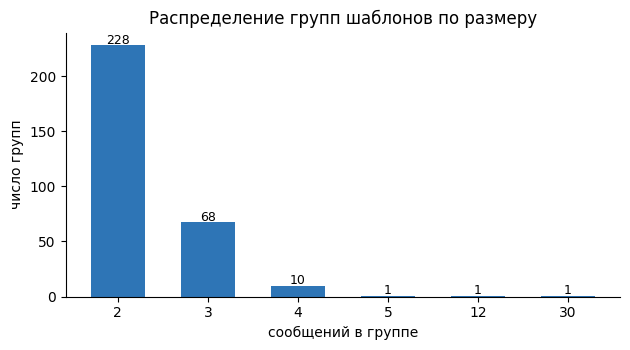

In [9]:
# Крупнейшая группа целиком: видно, что меняется только номер или сумма
if len(template_groups):
    biggest = template_groups.idxmax()
    sample = df.loc[df.text_norm == biggest, ["label", "text"]].head(6)
    print("Крупнейшая группа шаблонов:", int(template_groups.max()), "сообщений\n")
    display(sample)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
sizes = template_groups.value_counts().sort_index()
ax.bar(sizes.index.astype(str), sizes.values, color="#2E75B6", width=0.6)
for x, v in enumerate(sizes.values):
    ax.text(x, v + 1, str(v), ha="center", fontsize=9)
ax.set_title("Распределение групп шаблонов по размеру")
ax.set_xlabel("сообщений в группе")
ax.set_ylabel("число групп")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "03_sms_duplicate_groups.png", dpi=160)
plt.show()

## 6. Простые признаки

Проверяется, насколько классы разделяются поверхностными признаками: наличие ссылки,
номера телефона, суммы, валюты, слов в верхнем регистре. Результат нужен для двух
целей: (1) обосновать выбор TF-IDF как базовой модели; (2) показать, что обогащение
данными обязано приносить случаи, где признаки конфликтуют с меткой.

/tmp/ipykernel_1953/4102894607.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "есть ссылка": df["text"].str.contains(URL_RE, regex=True),


,"доля, % (ham)","доля, % (spam)"
есть ссылка,0.0,13.9
есть номер телефона,0.1,55.0
есть число,12.3,91.7
есть валюта,0.4,34.8
есть слово в верхнем регистре,7.2,70.4


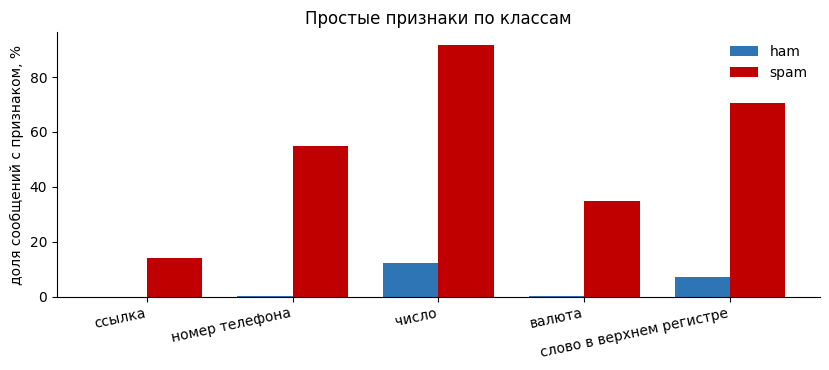

In [10]:
feat = pd.DataFrame({
    "label": df["label"],
    "есть ссылка": df["text"].str.contains(URL_RE, regex=True),
    "есть номер телефона": df["text"].str.contains(PHONE_RE, regex=True),
    "есть число": df["text"].str.contains(NUM_RE, regex=True),
    "есть валюта": df["text"].str.contains(CURRENCY_RE, regex=True),
    "есть слово в верхнем регистре": df["text"].str.contains(UPPER_WORD_RE, regex=True),
})

flag_cols = [c for c in feat.columns if c != "label"]
flag_table = feat.groupby("label")[flag_cols].mean().T.mul(100).round(1)
flag_table.columns = [f"доля, % ({c})" for c in flag_table.columns]
display(flag_table)
flag_table.to_csv(TABLES / "sms_feature_flags.csv")

fig, ax = plt.subplots(figsize=(8.4, 3.8))
x = np.arange(len(flag_cols))
w = 0.38
for i, label in enumerate(("ham", "spam")):
    ax.bar(x + (i - 0.5) * w, feat.loc[feat.label == label, flag_cols].mean() * 100,
           width=w, label=label, color=["#2E75B6", "#C00000"][i])
ax.set_xticks(x)
ax.set_xticklabels([c.replace("есть ", "") for c in flag_cols], rotation=12, ha="right")
ax.set_ylabel("доля сообщений с признаком, %")
ax.set_title("Простые признаки по классам")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "04_sms_feature_flags.png", dpi=160)
plt.show()

## 7. Лексический состав

Размер словаря и доля редких токенов определяют, насколько устойчив TF-IDF: при
`min_df = 1` модель запоминает шаблоны, при `min_df >= 2` — обобщает. Здесь же
проверяется, какие токены дают максимальный вклад в разделение классов.

Токенов всего (без минимальной частоты): 13627
Размер словаря при min_df=1:  8713 (доля от полного: 63.94%)
Размер словаря при min_df=2:  4213 (доля от полного: 30.92%)


Размер словаря при min_df=5:  1813 (доля от полного: 13.30%)
Средняя доля hapax-токенов в сообщении: 0.159


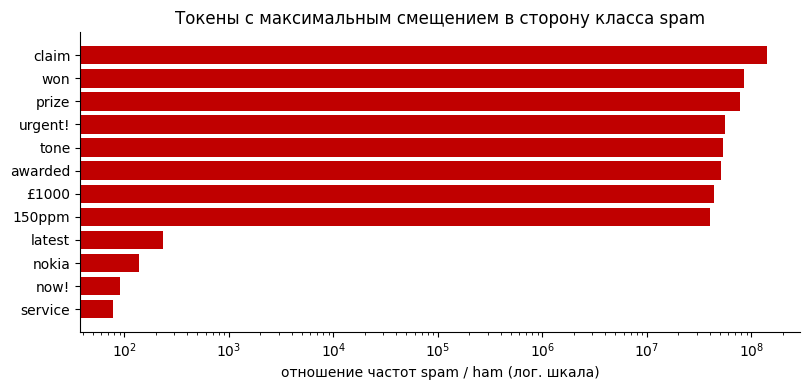

,spam/ham
claim,141900937.1
won,85676037.5
prize,77643909.0
urgent!,56224899.6
tone,53547523.4
awarded,50870147.3
£1000,44176706.8
150ppm,40160642.6
latest,232.6
nokia,137.9


In [11]:
counter = {label: pd.Series(" ".join(df.loc[df.label == label, "text"].str.lower()).split()).value_counts()
           for label in ("ham", "spam")}

vocab_all = set(counter["ham"].index) | set(counter["spam"].index)
print(f"Токенов всего (без минимальной частоты): {len(vocab_all)}")
for k in (1, 2, 5):
    v = TfidfVectorizer(min_df=k, lowercase=True).fit(df["text"])
    print(f"Размер словаря при min_df={k}: {v.vocabulary_.__len__():5d} "
          f"(доля от полного: {v.vocabulary_.__len__() / len(vocab_all):.2%})")

# Доля сообщений, состоящих только из слов, встречающихся один раз
rare = set(counter["ham"][counter["ham"] == 1].index) | set(counter["spam"][counter["spam"] == 1].index)
tokens_per_msg = df["text"].str.lower().str.split()
share_rare = tokens_per_msg.apply(lambda t: np.mean([w in rare for w in t]) if t else 0)
print(f"Средняя доля hapax-токенов в сообщении: {share_rare.mean():.3f}")

# Топ-10 «спам-индикаторов»: отношение частот с поправкой
def rate(w, label, n):
    return counter[label].get(w, 0) / n

n_ham, n_spam = (df.label == "ham").sum(), (df.label == "spam").sum()
cand = [w for w in vocab_all if counter["spam"].get(w, 0) >= 30]
scored = pd.Series({w: rate(w, "spam", n_spam) / max(rate(w, "ham", n_ham), 1e-9) for w in cand})
top_spam_tokens = scored.sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(8.2, 4.0))
ax.barh(top_spam_tokens.index[::-1], top_spam_tokens.values[::-1], color="#C00000")
ax.set_xlabel("отношение частот spam / ham (лог. шкала)")
ax.set_xscale("log")
ax.set_title("Токены с максимальным смещением в сторону класса spam")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "05_sms_top_tokens.png", dpi=160)
plt.show()
display(top_spam_tokens.round(1).to_frame("spam/ham"))

## 8. Влияние утечки на оценку качества модели

Проверка на реальных данных: одна и та же модель (TF-IDF + логистическая регрессия)
обучается при двух схемах разбиения — случайной по строкам (`StratifiedKFold`)
и групповой по шаблонам (`StratifiedGroupKFold`). Разница в macro-F1 показывает,
насколько случайное разбиение завышает результат. Этот замер определяет схему
кросс-валидации во всех четырёх вариантах эксперимента (A–D).

In [12]:
pipe = lambda: Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

y = df["label"]

split_results = []
SPLIT_VARIANTS = (
    ("случайное разбиение (StratifiedKFold)",
     StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), None),
    ("групповое разбиение (StratifiedGroupKFold)",
     StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), df["group_id"]),
)

for name, splitter, groups in SPLIT_VARIANTS:
    y_pred = cross_val_predict(pipe(), df["text"], y, cv=splitter, groups=groups, n_jobs=-1)
    split_results.append({
        "схема разбиения": name,
        "macro-F1": f1_score(y, y_pred, average="macro"),
        "F1 класса spam": f1_score(y, y_pred, pos_label="spam"),
        "Cohen's kappa": cohen_kappa_score(y, y_pred),
        "ошибок, шт.": int((y != y_pred).sum()),
    })

split_table = pd.DataFrame(split_results).set_index("схема разбиения").round(4)
display(split_table)
split_table.to_csv(TABLES / "sms_baseline_split_effect.csv")

delta = (split_table.loc["случайное разбиение (StratifiedKFold)", "macro-F1"]
         - split_table.loc["групповое разбиение (StratifiedGroupKFold)", "macro-F1"])
print(f"Завышение macro-F1 при случайном разбиении: {delta:+.4f}")

,macro-F1,F1 класса spam,Cohen's kappa,"ошибок, шт."
схема разбиения,,,,
случайное разбиение (StratifiedKFold),0.9292,0.8754,0.8587,166
групповое разбиение (StratifiedGroupKFold),0.9171,0.8536,0.8347,191


Завышение macro-F1 при случайном разбиении: +0.0121


## 9. Оценивание базовой линии: интервалы и повторная кросс-валидация

Метрика, полученная на одном разбиении, содержит две составляющие разброса:

1. **выборочная ошибка** — корпус рассматривается как выборка из совокупности сообщений;
2. **ошибка разбиения** — результат зависит от того, какие группы шаблонов попали в тестовые фолды.

Первая оценивается кластерным бутстрэпом по `group_id`: пересэмплируются группы целиком, а не строки.
При пересэмплировании строк копии шаблонов попадают и в обучающую, и в проверочную часть
бутстрэп-выборки, интервал сужается и перестаёт отражать реальную неопределённость.

Вторая оценивается повтором групповой кросс-валидации с разными `random_state`. Разброс macro-F1
между повторами — это тот уровень шума, ниже которого различие между вариантами эксперимента
интерпретировать нельзя.

Базовые линии, с которыми сравнивается любой вариант: константный ответ `ham`
(macro-F1 = 0,5, PR-AUC = доля спама) и TF-IDF + логистическая регрессия.

In [13]:
def make_model() -> Pipeline:
    """TF-IDF + логистическая регрессия: одна и та же модель во всех замерах."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])


def scores_at(y_true, proba, thr: float = 0.5) -> dict:
    """Метрики по вероятностям при фиксированном пороге решения."""
    pred = np.where(proba >= thr, "spam", "ham")
    prec, rec, f1_pos, _ = precision_recall_fscore_support(
        y_true, pred, labels=["spam"], average=None)
    return {
        "macro-F1": f1_score(y_true, pred, average="macro"),
        "F1 spam": float(f1_pos[0]),
        "precision spam": float(prec[0]),
        "recall spam": float(rec[0]),
        "PR-AUC": average_precision_score(y_true == "spam", proba),
        "ROC-AUC": roc_auc_score(y_true == "spam", proba),
        "Brier": brier_score_loss((y_true == "spam").astype(int), proba),
    }


def oof_proba(df_, y_, splitter):
    """Вероятности класса spam вне обучения по фолдам и номер фолда каждой строки."""
    proba = np.zeros(len(df_))
    fold = np.full(len(df_), -1)
    for k, (tr, te) in enumerate(splitter.split(df_["text"], y_, groups=df_["group_id"])):
        model = make_model().fit(df_["text"].iloc[tr], y_.iloc[tr])
        assert list(model.classes_) == ["ham", "spam"], model.classes_
        proba[te] = model.predict_proba(df_["text"].iloc[te])[:, 1]
        fold[te] = k
    assert (fold >= 0).all(), "часть строк не попала ни в один фолд"
    return proba, fold


def cluster_bootstrap(y_true, proba, groups_, n_boot: int = 500, seed: int = RANDOM_STATE):
    """Бутстрэп по группам: интервалы метрик и стандартные ошибки."""
    codes, uniq = pd.factorize(groups_)
    buckets = [np.flatnonzero(codes == k) for k in range(uniq.size)]
    rng = np.random.default_rng(seed)
    draws = pd.DataFrame([scores_at(y_true.take(idx), proba[idx])
                          for idx in (np.concatenate([buckets[k] for k in rng.integers(0, uniq.size, uniq.size)])
                                      for _ in range(n_boot))])
    ci = draws.quantile([0.025, 0.975]).T
    ci.columns = ["нижняя 95 %", "верхняя 95 %"]
    return ci, draws


N_REPEATS = 5
repeat_rows, oof_first, fold_first = [], None, None
for rep in range(N_REPEATS):
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + rep)
    proba_rep, fold_rep = oof_proba(df, y, splitter)
    if rep == 0:
        oof_first, fold_first = proba_rep, fold_rep
    repeat_rows.append({"повтор": rep + 1, "random_state": RANDOM_STATE + rep, **scores_at(y, proba_rep)})

repeat_table = pd.DataFrame(repeat_rows).set_index("повтор")
display(repeat_table.round(4))
repeat_table.to_csv(TABLES / "sms_cv_repeats.csv")

ci_macro, draws = cluster_bootstrap(y, oof_first, df["group_id"], n_boot=500)
point = pd.Series(scores_at(y, oof_first), name="точечная оценка")
baseline_ci = pd.concat([point, ci_macro], axis=1).round(4)
baseline_ci["стандартная ошибка"] = draws.std().round(4)
display(baseline_ci)
baseline_ci.to_csv(TABLES / "sms_baseline_ci.csv")

baseline_const = pd.Series({
    "macro-F1": 0.5,
    "F1 spam": 0.0,
    "precision spam": float(share["spam"]),
    "recall spam": 1.0,
    "PR-AUC": float(share["spam"]),
    "ROC-AUC": 0.5,
    "Brier": float(share["spam"] * (1 - share["spam"])),
}, name="константный ответ ham")
display(baseline_const.round(4).to_frame())

spread = repeat_table.agg(["mean", "std", "min", "max"]).T.round(4)
display(spread)
print(f"Разброс macro-F1 между повторами CV (ошибка разбиения): SD = {repeat_table['macro-F1'].std():.4f}")
print(f"Стандартная ошибка macro-F1 (кластерный бутстрэп):      {draws['macro-F1'].std():.4f}")
print("Различие вариантов, меньшее суммы этих величин, не интерпретируется.")

,random_state,macro-F1,F1 spam,precision spam,recall spam,PR-AUC,ROC-AUC,Brier
повтор,,,,,,,,
1,42,0.9171,0.8536,0.9982,0.7456,0.9763,0.9916,0.0291
2,43,0.9182,0.8556,0.9964,0.7497,0.9761,0.9913,0.0290
3,44,0.9211,0.8608,0.9965,0.7577,0.9769,0.9918,0.0287
4,45,0.9234,0.8649,0.9982,0.7631,0.9769,0.9920,0.0286
5,46,0.9216,0.8617,0.9965,0.7590,0.9773,0.9921,0.0287


,точечная оценка,нижняя 95 %,верхняя 95 %,стандартная ошибка
macro-F1,0.9171,0.9018,0.9307,0.0073
F1 spam,0.8536,0.8270,0.8778,0.0132
precision spam,0.9982,0.9931,1.0000,0.0019
recall spam,0.7456,0.7056,0.7833,0.0200
PR-AUC,0.9763,0.9684,0.9835,0.0039
ROC-AUC,0.9916,0.9878,0.9950,0.0019
Brier,0.0291,0.0262,0.0322,0.0015


,константный ответ ham
macro-F1,0.5000
F1 spam,0.0000
precision spam,0.1340
recall spam,1.0000
PR-AUC,0.1340
ROC-AUC,0.5000
Brier,0.1161


,mean,std,min,max
random_state,44.0000,1.5811,42.0000,46.0000
macro-F1,0.9203,0.0026,0.9171,0.9234
F1 spam,0.8593,0.0046,0.8536,0.8649
precision spam,0.9972,0.0010,0.9964,0.9982
recall spam,0.7550,0.0071,0.7456,0.7631
PR-AUC,0.9767,0.0005,0.9761,0.9773
ROC-AUC,0.9918,0.0003,0.9913,0.9921
Brier,0.0288,0.0002,0.0286,0.0291


Разброс macro-F1 между повторами CV (ошибка разбиения): SD = 0.0026
Стандартная ошибка macro-F1 (кластерный бутстрэп):      0.0073
Различие вариантов, меньшее суммы этих величин, не интерпретируется.


## 10. Калибровка вероятностей и выбор порога решения

Порог 0,5 не имеет содержательного обоснования: при доле спама 13,4 % он даёт много ложных
срабатываний, а в фильтре стоимость пропуска спама и ложной блокировки обычного сообщения
различается. Раздел фиксирует три величины, которые нужны для выбора решения:

* **Brier score** — средняя квадратичная ошибка вероятности, оценивает калибровку в целом;
* **таблица надёжности** — сравнение предсказанной вероятности с наблюдённой частотой по бинам:
  модель, у которой средняя вероятность в бине 0,8, а фактическая частота 0,5, не калибрована;
* **кривая порога** — F1, precision, recall, balanced accuracy и ожидаемые потери при матрице стоимостей.

Порог, выбранный на тех же данных, где измеряется метрика, даёт завышенную оценку. Поэтому
используются три величины: порог 0,5 (по умолчанию, для сравнения), порог по максимуму метрики
на всех предсказаниях вне обучения (оптимистичная граница) и **вложенная процедура** — порог
выбирается на четырёх фолдах и применяется к пятому, отложенному. Только вложенная оценка
показывает, что даёт выбор порога на новых данных.

,сообщений,средняя вероятность,наблюдённая частота,разность,вес
bin,,,,,
0,558,0.0215,0.0000,0.0215,0.1001
1,557,0.0302,0.0018,0.0285,0.0999
2,557,0.0371,0.0000,0.0371,0.0999
3,558,0.0433,0.0018,0.0415,0.1001
4,557,0.0502,0.0036,0.0466,0.0999
5,557,0.0588,0.0036,0.0552,0.0999
6,558,0.0699,0.0036,0.0663,0.1001
7,557,0.0896,0.0180,0.0717,0.0999
8,557,0.2250,0.3088,0.0838,0.0999


Brier score: 0.0291
Ожидаемая ошибка калибровки ECE: 0.0719


,порог,macro-F1,F1 spam,precision spam,recall spam,balanced accuracy,"ложных срабатываний, шт.","пропусков спама, шт.",ожидаемые потери
0,0.05,0.5369,0.3904,0.2428,0.9960,0.7577,2320,3,2335.0
2,0.15,0.9292,0.8793,0.8074,0.9652,0.9648,172,26,302.0
4,0.25,0.9626,0.9352,0.9429,0.9277,0.9595,42,54,312.0
6,0.35,0.9553,0.9220,0.9804,0.8701,0.9337,13,97,498.0
8,0.45,0.9372,0.8895,0.9967,0.8032,0.9014,2,147,737.0
10,0.55,0.9011,0.8248,0.9981,0.7028,0.8513,1,222,1111.0
12,0.65,0.8441,0.7209,1.0000,0.5636,0.7818,0,326,1630.0
14,0.75,0.7326,0.5134,1.0000,0.3454,0.6727,0,489,2445.0
16,0.85,0.5723,0.2086,1.0000,0.1165,0.5582,0,660,3300.0
18,0.95,0.4696,0.0107,1.0000,0.0054,0.5027,0,743,3715.0


,фолд,выбранный порог,сообщений вне фолда
0,0,0.25,4444
1,1,0.25,4441
2,2,0.25,4473
3,3,0.25,4467
4,4,0.25,4471


,"порог 0,50 (по умолчанию)",порог по всем OOF (оптимистично),"порог, выбранный вложенно"
macro-F1,0.9171,0.9626,0.9626
F1 spam,0.8536,0.9352,0.9352
precision spam,0.9982,0.9429,0.9429
recall spam,0.7456,0.9277,0.9277


Порог по всем OOF-предсказаниям: 0.25. Выбор устойчив: во всех фолдах вложенная процедура дала тот же порог, поэтому оценка не завышается. Иначе вложенная оценка была бы ниже оптимистичной.
Вложенная оценка macro-F1: 0.9626 против 0.9171 при пороге 0,50; разница +0.0455.
Порог по минимуму потерь при COST_FP = 1.0, COST_FN = 5.0: 0.20 (потери 274)


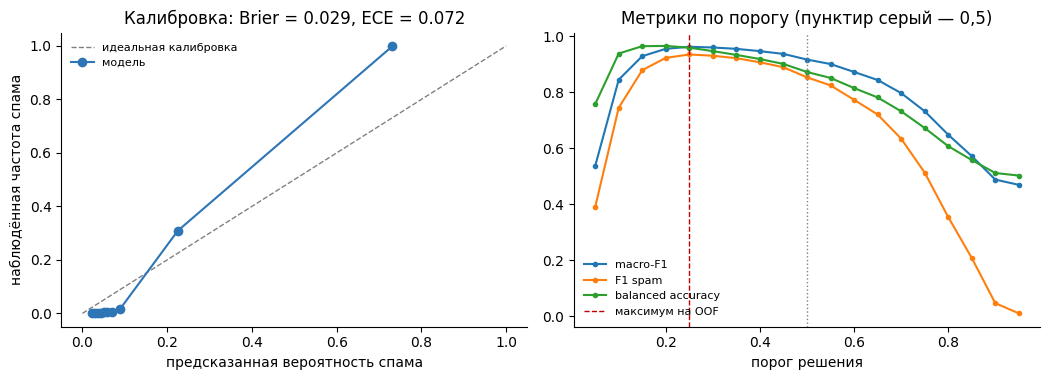

In [14]:
def reliability_table(y_true, proba, n_bins: int = 10) -> pd.DataFrame:
    """Таблица надёжности: предсказанная вероятность против наблюдённой частоты."""
    edges = np.unique(np.quantile(proba, np.linspace(0, 1, n_bins + 1)))
    bins = pd.cut(proba, bins=edges, include_lowest=True, labels=False)
    t = pd.DataFrame({"bin": bins, "proba": proba, "spam": (y_true == "spam").astype(int)})
    table = (t.groupby("bin")
             .agg(**{"сообщений": ("spam", "size"),
                     "средняя вероятность": ("proba", "mean"),
                     "наблюдённая частота": ("spam", "mean")}))
    table["разность"] = (table["средняя вероятность"] - table["наблюдённая частота"]).abs()
    table["вес"] = table["сообщений"] / table["сообщений"].sum()
    return table.round(4)


calibration_table = reliability_table(y, oof_first)
display(calibration_table)
ece = float((calibration_table["разность"] * calibration_table["вес"]).sum())
print(f"Brier score: {scores_at(y, oof_first)['Brier']:.4f}")
print(f"Ожидаемая ошибка калибровки ECE: {ece:.4f}")
calibration_table.to_csv(TABLES / "sms_calibration.csv")

COST_FP, COST_FN = 1.0, 5.0     # условная матрица стоимостей: пропуск спама дороже
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.05), 2)


def threshold_scan(y_true, proba, thresholds=THRESHOLDS) -> pd.DataFrame:
    """Метрики и потери при каждом пороге решения."""
    rows = []
    for thr in thresholds:
        pred_bool = proba >= thr
        pred = np.where(pred_bool, "spam", "ham")
        fp = int((pred_bool & (y_true == "ham")).sum())
        fn = int((~pred_bool & (y_true == "spam")).sum())
        tp = int((pred_bool & (y_true == "spam")).sum())
        tn = int((~pred_bool & (y_true == "ham")).sum())
        rows.append({
            "порог": float(thr),
            "macro-F1": f1_score(y_true, pred, average="macro"),
            "F1 spam": f1_score(y_true, pred, pos_label="spam"),
            "precision spam": tp / (tp + fp) if tp + fp else 0.0,
            "recall spam": tp / (tp + fn) if tp + fn else 0.0,
            "balanced accuracy": 0.5 * (tp / (tp + fn) + tn / (tn + fp)),
            "ложных срабатываний, шт.": fp,
            "пропусков спама, шт.": fn,
            "ожидаемые потери": COST_FP * fp + COST_FN * fn,
        })
    return pd.DataFrame(rows).round(4)


threshold_table = threshold_scan(y, oof_first)
display(threshold_table.iloc[::2])
threshold_table.to_csv(TABLES / "sms_thresholds.csv", index=False)

best_f1 = threshold_table.loc[threshold_table["macro-F1"].idxmax()]
best_cost = threshold_table.loc[threshold_table["ожидаемые потери"].idxmin()]
at_half = threshold_table.loc[threshold_table["порог"] == 0.5].iloc[0]

# Вложенная процедура: порог выбирается на остальных фолдах и применяется к отложенному.
pred_nested = np.empty(len(df), dtype=object)
chosen = []
for f in np.unique(fold_first):
    outside = fold_first != f
    thr_f = float(threshold_scan(y[outside], oof_first[outside])
                  .pipe(lambda t: t.loc[t["macro-F1"].idxmax(), "порог"]))
    chosen.append({"фолд": int(f), "выбранный порог": thr_f,
                   "сообщений вне фолда": int(outside.sum())})
    pred_nested[fold_first == f] = np.where(oof_first[fold_first == f] >= thr_f, "spam", "ham")
nested_table = pd.DataFrame(chosen)
display(nested_table)

nested_scores = {
    "macro-F1": f1_score(y, pred_nested, average="macro"),
    "F1 spam": f1_score(y, pred_nested, pos_label="spam"),
    "precision spam": float(precision_recall_fscore_support(y, pred_nested, labels=["spam"], average=None)[0][0]),
    "recall spam": float(precision_recall_fscore_support(y, pred_nested, labels=["spam"], average=None)[1][0]),
}
comparison = pd.DataFrame({
    "порог 0,50 (по умолчанию)": at_half[["macro-F1", "F1 spam", "precision spam", "recall spam"]],
    "порог по всем OOF (оптимистично)": best_f1[["macro-F1", "F1 spam", "precision spam", "recall spam"]],
    "порог, выбранный вложенно": pd.Series(nested_scores),
}).astype(float).round(4)
display(comparison)
comparison.to_csv(TABLES / "sms_threshold_selection.csv")
stable = np.allclose(nested_table["выбранный порог"].to_numpy(), best_f1["порог"])
print(f"Порог по всем OOF-предсказаниям: {best_f1['порог']:.2f}. "
      + ("Выбор устойчив: во всех фолдах вложенная процедура дала тот же порог, поэтому оценка "
         "не завышается. Иначе вложенная оценка была бы ниже оптимистичной."
         if stable else
         "Выбор неустойчив: вложенная процедура даёт другие пороги, и оптимистичная оценка завышена."))
print(f"Вложенная оценка macro-F1: {nested_scores['macro-F1']:.4f} против {at_half['macro-F1']:.4f} "
      f"при пороге 0,50; разница {(nested_scores['macro-F1'] - at_half['macro-F1']):+.4f}.")
print(f"Порог по минимуму потерь при COST_FP = {COST_FP}, COST_FN = {COST_FN}: "
      f"{best_cost['порог']:.2f} (потери {int(best_cost['ожидаемые потери'])})")

fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.9))
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="идеальная калибровка")
axes[0].plot(calibration_table["средняя вероятность"], calibration_table["наблюдённая частота"],
             marker="o", color="#2E75B6", label="модель")
axes[0].set_xlabel("предсказанная вероятность спама")
axes[0].set_ylabel("наблюдённая частота спама")
axes[0].set_title(f"Калибровка: Brier = {scores_at(y, oof_first)['Brier']:.3f}, ECE = {ece:.3f}")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(threshold_table["порог"], threshold_table["macro-F1"], marker=".", label="macro-F1")
axes[1].plot(threshold_table["порог"], threshold_table["F1 spam"], marker=".", label="F1 spam")
axes[1].plot(threshold_table["порог"], threshold_table["balanced accuracy"], marker=".", label="balanced accuracy")
axes[1].axvline(0.5, ls=":", color="grey", lw=1)
axes[1].axvline(float(best_f1["порог"]), ls="--", color="#C00000", lw=1, label="максимум на OOF")
axes[1].set_xlabel("порог решения")
axes[1].set_title("Метрики по порогу (пунктир серый — 0,5)")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "06_sms_calibration.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. Чувствительность эксперимента: какой прирост различим

Обогащение на 50–100 сообщений — это 0,9–1,8 % корпуса. Прежде чем объявлять прирост качества,
нужно проверить, различим ли он на имеющейся выборке. Расчёт строится на стандартной ошибке
метрики: при доверительной вероятности 95 % и мощности 80 % минимально различимый прирост
составляет примерно `2,77 × SE` (парное сравнение на одинаковых фолдах), а требуемый объём
выборки масштабируется как `n · (SE · 2,77 / δ)²`, поскольку `SE ∝ 1/√n`.

Для сравнения двух вариантов на одном и том же тесте используется точный тест МакНемара:
сравниваются только несогласованные пары (один вариант верен, второй ошибается). Критическое
число несогласованных пар определяется биномиальным распределением, а не нормальным приближением,
поскольку при объёме теста 100–300 пар их немного.

In [15]:
import math


def mcnemar_exact(y_true, pred_a, pred_b) -> tuple[int, int, float]:
    """Точный тест МакНемара: (a верен / b ошибается, наоборот, p-значение)."""
    ok_a, ok_b = pred_a == y_true, pred_b == y_true
    n01 = int((~ok_a & ok_b).sum())
    n10 = int((ok_a & ~ok_b).sum())
    n = n01 + n10
    if n == 0:
        return n01, n10, 1.0
    k = min(n01, n10)
    p = min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)
    return n01, n10, p


def mcnemar_critical(n_pairs: int, alpha: float = 0.05) -> int:
    """Наибольшее число несогласованных пар в меньшинстве, при котором различие значимо."""
    best = -1
    for k in range(n_pairs // 2 + 1):
        p = 2 * sum(math.comb(n_pairs, i) for i in range(k + 1)) / 2 ** n_pairs
        if p < alpha:
            best = k
    return best


se = draws.std()
MDD_FACTOR = 2.80          # 1,96 (значимость 5 %) + 0,84 (мощность 80 %)
mdd = (MDD_FACTOR * se).round(4)
power_table = pd.DataFrame({"метрика": mdd.index,
                            "стандартная ошибка": se.round(4).values,
                            "минимально различимый прирост": mdd.values})
display(power_table)
power_table.to_csv(TABLES / "sms_power_analysis.csv", index=False)

targets = pd.DataFrame({"целевой прирост macro-F1": [0.005, 0.010, 0.020, 0.050]})
targets["требуемый объём корпуса"] = (len(df) * (mdd["macro-F1"] / targets["целевой прирост macro-F1"]) ** 2).round(0).astype(int)
targets["кратность к текущему объёму"] = (targets["требуемый объём корпуса"] / len(df)).round(2)
targets["текущий корпус, % от требуемого"] = (100 / targets["кратность к текущему объёму"]).round(1)
display(targets)
targets.to_csv(TABLES / "sms_power_analysis_sample_size.csv", index=False)

print("Изменение точности при добавлении сообщений (SE ~ 1/sqrt(n)):")
for k in (50, 100, 300, 1000):
    se_new = se["macro-F1"] * math.sqrt(len(df) / (len(df) + k))
    print(f"  +{k:4d} сообщений ({k / len(df):.1%} корпуса): SE {se['macro-F1']:.5f} -> {se_new:.5f} "
          f"({(se_new / se['macro-F1'] - 1) * 100:+.2f} %), минимально различимый прирост {MDD_FACTOR * se_new:.4f}")

pairs = pd.DataFrame({"несогласованных пар": [10, 15, 20, 30, 50]})
pairs["максимум пар в меньшинстве"] = [mcnemar_critical(n) for n in pairs["несогласованных пар"]]
pairs["необходимый перевес, пар"] = pairs["несогласованных пар"] - pairs["максимум пар в меньшинстве"]
pairs["перевес, % пар"] = (pairs["необходимый перевес, пар"] / pairs["несогласованных пар"] * 100).round(1)
print("Критические значения теста МакНемара (alpha = 0,05):")
display(pairs)
pairs.to_csv(TABLES / "sms_mcnemar_critical.csv", index=False)
print(f"Минимально различимый прирост macro-F1: {mdd['macro-F1']:.4f}. Добавление 100 сообщений "
      f"уменьшает стандартную ошибку менее чем на 1 %, то есть ожидаемый прирост остаётся ниже "
      f"минимально различимого. Утверждение о приросте на полном корпусе данными не подкрепляется; "
      f"обогащение оценивается на отдельном тесте из собранных сообщений, а варианты сравниваются "
      f"по несогласованным парам (тест МакНемара).")

,метрика,стандартная ошибка,минимально различимый прирост
0,macro-F1,0.0073,0.0205
1,F1 spam,0.0132,0.0369
2,precision spam,0.0019,0.0052
3,recall spam,0.0200,0.0559
4,PR-AUC,0.0039,0.0109
5,ROC-AUC,0.0019,0.0054
6,Brier,0.0015,0.0042


,целевой прирост macro-F1,требуемый объём корпуса,кратность к текущему объёму,"текущий корпус, % от требуемого"
0,0.005,93699,16.81,5.9
1,0.010,23425,4.20,23.8
2,0.020,5856,1.05,95.2
3,0.050,937,0.17,588.2


Изменение точности при добавлении сообщений (SE ~ 1/sqrt(n)):
  +  50 сообщений (0.9% корпуса): SE 0.00733 -> 0.00729 (-0.45 %), минимально различимый прирост 0.0204
  + 100 сообщений (1.8% корпуса): SE 0.00733 -> 0.00726 (-0.89 %), минимально различимый прирост 0.0203
  + 300 сообщений (5.4% корпуса): SE 0.00733 -> 0.00714 (-2.59 %), минимально различимый прирост 0.0200
  +1000 сообщений (17.9% корпуса): SE 0.00733 -> 0.00675 (-7.92 %), минимально различимый прирост 0.0189
Критические значения теста МакНемара (alpha = 0,05):


,несогласованных пар,максимум пар в меньшинстве,"необходимый перевес, пар","перевес, % пар"
0,10,1,9,90.0
1,15,3,12,80.0
2,20,5,15,75.0
3,30,9,21,70.0
4,50,17,33,66.0


Минимально различимый прирост macro-F1: 0.0205. Добавление 100 сообщений уменьшает стандартную ошибку менее чем на 1 %, то есть ожидаемый прирост остаётся ниже минимально различимого. Утверждение о приросте на полном корпусе данными не подкрепляется; обогащение оценивается на отдельном тесте из собранных сообщений, а варианты сравниваются по несогласованным парам (тест МакНемара).


## 12. Регламент эксперимента и таблица результатов вариантов A–D

Регламент фиксируется до получения результатов: изменение схемы разбиения, порога или набора
метрик после просмотра чисел делает сравнение вариантов недействительным.

| Элемент протокола | Значение |
|---|---|
| Данные | UCI SMS Spam Collection, SHA-256 из раздела 1 |
| Схема разбиения | `StratifiedGroupKFold`, 5 фолдов, группы по `group_id` |
| Повторы | 5 (значения `RANDOM_STATE + 0…4`), отчёт по среднему и стандартному отклонению |
| Основная метрика | macro-F1 |
| Дополнительные метрики | F1 класса spam, PR-AUC, ROC-AUC, Brier |
| Порог решения | выбирается на валидационной части (вложенно по фолдам), на тесте не меняется |
| Интервалы | кластерный бутстрэп по `group_id`, 500 повторов, 95 % |
| Сравнение вариантов | парные предсказания на одном тесте, точный тест МакНемара |
| Условие утверждения о превосходстве | интервал разности не содержит нуля и p < 0,05 |

Варианты эксперимента: A — базовая модель на исходных данных; B — с добавлением собранных
сообщений только в обучение; C — с добавлением в обучение и в тест (контроль утечки);
D — с добавлением и переобучением порога. Все варианты используют одну схему разбиения и один
набор фолдов, иначе различие метрик нельзя отнести к данным.

In [16]:
RESULT_COLUMNS = ["вариант", "метрика", "точечная оценка", "нижняя 95 %", "верхняя 95 %",
                  "n сообщений", "схема разбиения", "random_state", "дата", "примечание"]

results_template = pd.DataFrame(
    [{"вариант": v, "метрика": m} for v in ("A", "B", "C", "D")
     for m in ("macro-F1", "F1 spam", "PR-AUC", "Brier")],
    columns=RESULT_COLUMNS,
)
results_template.to_csv(TABLES / "sms_results_template.csv", index=False)
display(results_template.head(8))


def validate_results(table: pd.DataFrame) -> list[str]:
    """Проверка заполненной таблицы результатов перед переносом в отчёт."""
    problems = []
    missing = [c for c in RESULT_COLUMNS if c not in table.columns]
    if missing:
        return [f"нет колонок: {missing}"]
    filled = table.dropna(subset=["точечная оценка"])
    for _, r in filled.iterrows():
        if pd.isna(r["нижняя 95 %"]) or pd.isna(r["верхняя 95 %"]):
            problems.append(f"{r['вариант']} / {r['метрика']}: нет интервала")
        if pd.isna(r["n сообщений"]):
            problems.append(f"{r['вариант']} / {r['метрика']}: не указан объём выборки")
        if r["нижняя 95 %"] > r["точечная оценка"] or r["верхняя 95 %"] < r["точечная оценка"]:
            problems.append(f"{r['вариант']} / {r['метрика']}: точечная оценка вне интервала")
    if "A" in set(filled["вариант"]) and "B" in set(filled["вариант"]):
        a = filled[filled.вариант == "A"].set_index("метрика")
        b = filled[filled.вариант == "B"].set_index("метрика")
        common = a.index.intersection(b.index)
        if len(common) and (a.loc[common, "random_state"] != b.loc[common, "random_state"]).any():
            problems.append("варианты A и B оценены на разных фолдах: сравнение недействительно")
    return problems


print("Пустая таблица: проблем не найдено" if not validate_results(results_template)
      else validate_results(results_template))
print("Порядок работы: заполнить таблицу по вариантам, выполнить validate_results, "
      "перенести значения в отчёт без ручного пересчёта.")

,вариант,метрика,точечная оценка,нижняя 95 %,верхняя 95 %,n сообщений,схема разбиения,random_state,дата,примечание
0,A,macro-F1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A,F1 spam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A,PR-AUC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,A,Brier,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,B,macro-F1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,B,F1 spam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,B,PR-AUC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,B,Brier,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Пустая таблица: проблем не найдено
Порядок работы: заполнить таблицу по вариантам, выполнить validate_results, перенести значения в отчёт без ручного пересчёта.


## 13. Сводка результатов

Таблица собирается программно из вычисленных выше величин; значения переносятся
в раздел «Анализ данных» отчёта без ручного пересчёта.

In [17]:
summary = pd.DataFrame(
    [
        ("Объём набора, сообщений", len(df)),
        ("Класс ham, сообщений", int(counts["ham"])),
        ("Класс spam, сообщений", int(counts["spam"])),
        ("Доля класса spam", f"{share['spam']:.1%}"),
        ("Уникальных текстов", int(df['text'].nunique())),
        ("Точных дубликатов", n_exact_dup),
        ("Групп шаблонов", int(len(template_groups))),
        ("Уникальных group_id", int(df['group_id'].nunique())),
        ("Медианная длина, символов (ham / spam)",
         f"{df.loc[df.label == 'ham', 'len_chars'].median():.0f} / {df.loc[df.label == 'spam', 'len_chars'].median():.0f}"),
        ("Сообщений со ссылкой, % (ham / spam)",
         f"{feat.loc[feat.label == 'ham', 'есть ссылка'].mean():.1%} / {feat.loc[feat.label == 'spam', 'есть ссылка'].mean():.1%}"),
        ("Сообщений с номером телефона, % (ham / spam)",
         f"{feat.loc[feat.label == 'ham', 'есть номер телефона'].mean():.1%} / {feat.loc[feat.label == 'spam', 'есть номер телефона'].mean():.1%}"),
        ("macro-F1, случайное разбиение", round(split_table.iloc[0]['macro-F1'], 4)),
        ("macro-F1, групповое разбиение", round(split_table.iloc[1]['macro-F1'], 4)),
        ("macro-F1, 95 % ДИ (кластерный бутстрэп)",
         f"{baseline_ci.loc['macro-F1', 'нижняя 95 %']:.4f}–{baseline_ci.loc['macro-F1', 'верхняя 95 %']:.4f}"),
        ("PR-AUC, 95 % ДИ",
         f"{baseline_ci.loc['PR-AUC', 'нижняя 95 %']:.4f}–{baseline_ci.loc['PR-AUC', 'верхняя 95 %']:.4f}"),
        ("Brier score", round(float(baseline_ci.loc['Brier', 'точечная оценка']), 4)),
        ("Разброс macro-F1 между повторами CV (SD)", round(float(repeat_table['macro-F1'].std()), 4)),
        ("Минимально различимый прирост macro-F1", round(float(mdd['macro-F1']), 4)),
        ("Порог, выбранный вложенно (среднее по фолдам)", round(float(nested_table['выбранный порог'].mean()), 3)),
        ("macro-F1 при вложенном выборе порога", round(float(nested_scores['macro-F1']), 4)),
        ("PR-AUC константного ответа ham", round(float(share['spam']), 4)),
    ],
    columns=["показатель", "значение"],
)
display(summary)
summary.to_csv(TABLES / "sms_eda_summary.csv", index=False)

print("\nСохранённые артефакты:")
for p in sorted(TABLES.glob("sms_*.csv")):
    print(" ", p.relative_to(ROOT))
for p in sorted(FIGURES.glob("0*_sms_*.png")):
    print(" ", p.relative_to(ROOT))

,показатель,значение
0,"Объём набора, сообщений",5574
1,"Класс ham, сообщений",4827
2,"Класс spam, сообщений",747
3,Доля класса spam,13.4%
4,Уникальных текстов,5171
5,Точных дубликатов,403
6,Групп шаблонов,309
7,Уникальных group_id,5136
8,"Медианная длина, символов (ham / spam)",52 / 149
9,"Сообщений со ссылкой, % (ham / spam)",0.0% / 13.9%



Сохранённые артефакты:
  reports/tables/sms_baseline_ci.csv
  reports/tables/sms_baseline_split_effect.csv
  reports/tables/sms_calibration.csv
  reports/tables/sms_class_balance.csv
  reports/tables/sms_cv_repeats.csv
  reports/tables/sms_dataset_passport.csv
  reports/tables/sms_duplicates.csv
  reports/tables/sms_eda_summary.csv
  reports/tables/sms_feature_flags.csv
  reports/tables/sms_length_stats.csv
  reports/tables/sms_mcnemar_critical.csv
  reports/tables/sms_power_analysis.csv
  reports/tables/sms_power_analysis_sample_size.csv
  reports/tables/sms_results_template.csv
  reports/tables/sms_threshold_selection.csv
  reports/tables/sms_thresholds.csv
  reports/figures/01_sms_class_balance.png
  reports/figures/02_sms_length_dist.png
  reports/figures/03_sms_duplicate_groups.png
  reports/figures/04_sms_feature_flags.png
  reports/figures/05_sms_top_tokens.png
  reports/figures/06_sms_calibration.png


## 14. Выводы и следствия для дизайна эксперимента

1. Объём 5 574 сообщения при дисбалансе 86,6 % / 13,4 %: константный ответ даёт
   accuracy 0,866, поэтому accuracy из отчёта исключается, основная метрика — macro-F1.
2. В наборе присутствуют точные дубликаты и группы шаблонов. Разбиение выполняется
   по `group_id` (нормализованный текст), во всех четырёх вариантах эксперимента A–D.
3. Корпус — смесь доменов (форум Grumbletext, NUS SMS Corpus — Singlish, корпус
   Gómez Hidalgo). Стиль сообщений неоднороден уже в исходных данных; это ограничение
   обобщения и одновременно аргумент в пользу ручного добора «свежих» сообщений.
4. Данные 2011 года: нет smishing, мессенджеров, современных форматов ссылок.
   Собираемые вручную 50–100 сообщений на класс должны закрывать именно этот разрыв.
5. Добавление 100 сообщений даёт +2,1 % к классу ham и +13,4 % к классу spam.
   Эффект обогащения интерпретируется по классам отдельно, а не «в среднем».
6. Базовая линия TF-IDF + логистическая регрессия даёт macro-F1 с интервалом; интервал
   обязателен при сравнении вариантов, поскольку разброс между повторами кросс-валидации
   сопоставим с ожидаемым приростом от обогащения.
7. Порог 0,5 не является решением по умолчанию: выбор порога по валидационной части меняет
   соотношение precision и recall, а при матрице стоимостей — и ожидаемые потери. Порог
   фиксируется в регламенте раздела 12.
8. Обогащение 50–100 сообщениями оценивается на отдельном тесте, состоящем из собранных
   сообщений, а не на полном корпусе: на полном корпусе такой прирост меньше минимально
   различимого. Сравнение вариантов выполняется по несогласованным парам (тест МакНемара).
9. Названные величины используются как базовая линия: любой вариант B–D сравнивается
   с этими числами на одинаковой схеме кросс-валидации и с одинаковым seed.